# Notebook 2: Quantum Gates (H, X, and H twice)

*Quantum for Energy Academy | Lecture 5: Your First Quantum Program*  
*Prof. Lilia Tightiz, Department of Computer Engineering, Sejong University*

**Goals of this notebook**

1. Apply the Hadamard gate and read the counts.
2. Apply the X gate, predict the result, and verify it.
3. Apply two H gates, predict the result, and explain it.

Each experiment follows the same order: **predict, run, verify**.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram

SHOTS = 1024
SEED = 42
OUTPUT_DIR = Path("..") / "outputs"  # figures go to the lecture outputs folder
OUTPUT_DIR.mkdir(exist_ok=True)


def run_counts(circuit, shots=SHOTS, seed=SEED):
    """Run a circuit on the local sampler and return its counts."""
    sampler = StatevectorSampler(seed=seed)
    return sampler.run([circuit], shots=shots).result()[0].data.c.get_counts()

## 1. The Hadamard gate

$$H = \frac{1}{\sqrt{2}}\begin{bmatrix}1 & 1\\ 1 & -1\end{bmatrix}, \qquad
H|0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}.$$

Both **amplitudes** are $1/\sqrt{2} \approx 0.707$.
Both **probabilities** are $|1/\sqrt{2}|^2 = 0.5$.

In [2]:
h_state = QuantumCircuit(1)
h_state.h(0)
state = Statevector(h_state)
print("Amplitudes:   ", state.data)
print("Probabilities:", state.probabilities())

Amplitudes:    [0.70710678+0.j 0.70710678+0.j]
Probabilities: [0.5 0.5]


### The complete program

This is the program from slide 11 of the lecture.

In [3]:
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler

# 1. Build: one qubit, one classical bit
qc = QuantumCircuit(1, 1)
qc.h(0)  # Hadamard on qubit 0
qc.measure(0, 0)  # qubit 0 -> classical bit 0

# 2. Execute: 1,024 shots on a local simulator
sampler = StatevectorSampler(seed=42)
job = sampler.run([qc], shots=1024)
result = job.result()

# 3. Read the counts
counts = result[0].data.c.get_counts()
print(counts)

{'1': 509, '0': 515}


The order of the keys in the dictionary is not important. The table below sorts the outcomes.

In [4]:
print("Outcome | Counts | Frequency | Theory")
for outcome in ("0", "1"):
    print(f"   {outcome}    | {counts[outcome]:6d} |  {counts[outcome] / SHOTS:.4f}   | 0.5000")
print("Sum of counts:", sum(counts.values()))

Outcome | Counts | Frequency | Theory
   0    |    515 |  0.5029   | 0.5000
   1    |    509 |  0.4971   | 0.5000
Sum of counts: 1024


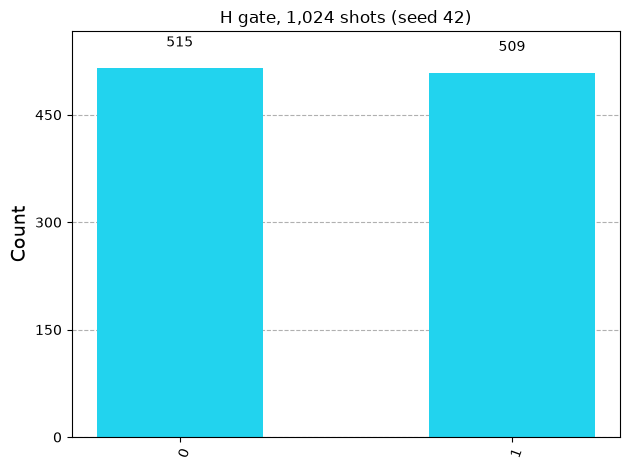

In [5]:
fig = plot_histogram(counts, color="#22D3EE", title="H gate, 1,024 shots (seed 42)")
fig.savefig(OUTPUT_DIR / "nb02_hadamard_histogram.png", dpi=200, bbox_inches="tight")
fig

## 2. The X gate

$$X = \begin{bmatrix}0 & 1\\ 1 & 0\end{bmatrix}, \qquad X|0\rangle = |1\rangle.$$

**Prediction:** every shot gives `1`. Write down your own prediction before you run the next cell.

In [6]:
qc_x = QuantumCircuit(1, 1)
qc_x.x(0)  # X (NOT) gate
qc_x.measure(0, 0)

counts_x = run_counts(qc_x)
print(qc_x.draw())
print("Counts:", counts_x)
assert counts_x == {"1": SHOTS}
print("Check passed: X|0> = |1>.")

     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 
Counts: {'1': 1024}
Check passed: X|0> = |1>.


## 3. Two H gates

$$HH|0\rangle = H\,\frac{|0\rangle + |1\rangle}{\sqrt{2}}
= \frac{1}{2}\big[(|0\rangle + |1\rangle) + (|0\rangle - |1\rangle)\big] = |0\rangle.$$

The two $|1\rangle$ terms cancel (destructive interference). The two $|0\rangle$ terms add up
(constructive interference). Two random coin flips never undo each other, but two H gates do.

**Prediction:** every shot gives `0`.

In [7]:
one_h = QuantumCircuit(1)
one_h.h(0)
two_h = QuantumCircuit(1)
two_h.h(0)
two_h.h(0)
print("After one H:", Statevector(one_h).data.round(6))
print("After two H:", Statevector(two_h).data.round(6))

After one H: [0.707107+0.j 0.707107+0.j]
After two H: [1.+0.j 0.+0.j]


In [8]:
qc_hh = QuantumCircuit(1, 1)
qc_hh.h(0)
qc_hh.h(0)
qc_hh.measure(0, 0)

counts_hh = run_counts(qc_hh)
print(qc_hh.draw())
print("Counts:", counts_hh)
assert counts_hh == {"0": SHOTS}
print("Check passed: HH|0> = |0>.")

     ┌───┐┌───┐┌─┐
  q: ┤ H ├┤ H ├┤M├
     └───┘└───┘└╥┘
c: 1/═══════════╩═
                0 
Counts: {'0': 1024}
Check passed: HH|0> = |0>.


## 4. Compare the three experiments

Same qubit, same measurement, same number of shots. Only the gates differ.

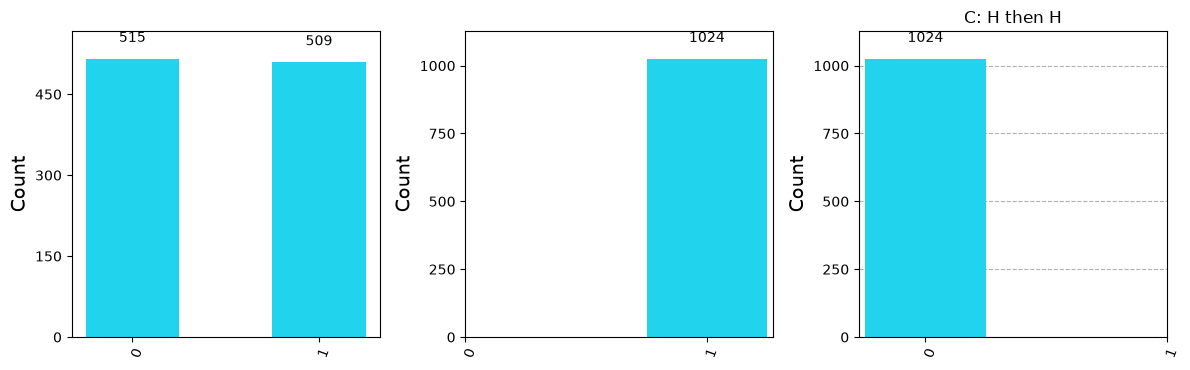

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
experiments = [("A: H", counts), ("B: X", counts_x), ("C: H then H", counts_hh)]
for ax, (title, experiment_counts) in zip(axes, experiments):
    full = {"0": experiment_counts.get("0", 0), "1": experiment_counts.get("1", 0)}
    plot_histogram(full, ax=ax, color="#22D3EE", title=title)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "nb02_three_experiments.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Try it yourself (optional challenge)

Predict the counts for each gate sequence, then check with `run_counts`:

| Sequence | Your prediction |
|---|---|
| X then H | ? |
| H then X | ? |
| X then H then H | ? |

Hint: $H|1\rangle = (|0\rangle - |1\rangle)/\sqrt{2}$.
The histogram shows probabilities only. It does not show the sign of an amplitude.

Solutions: `../exercises/instructor_solutions.md`.

In [10]:
# Your code here. Example:
# qc_try = QuantumCircuit(1, 1)
# qc_try.x(0)
# qc_try.h(0)
# qc_try.measure(0, 0)
# print(run_counts(qc_try))